In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [28]:
day5_path = "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"

df_day7 = pd.read_csv(
    day5_path,
    encoding="cp1252",
    low_memory=False
)

print("Day 5 dataset loaded successfully.")
print("Shape:", df_day7.shape)

display(df_day7.head())

Day 5 dataset loaded successfully.
Shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


In [29]:
required_columns = [
    "Delivery Status",
    "Order Status",
    "Shipping Mode",
    "Market",
    "Is_Delayed",
    "Shipping_Delay_Days",
    "Late_delivery_risk"
]

missing_columns = [
    col for col in required_columns
    if col not in df_day7.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available.")

All required columns are available.


## Day 7 Working Copy

In [30]:
df_day7 = df_day7.copy()

print("Day 7 working copy created.")
print("Shape:", df_day7.shape)

Day 7 working copy created.
Shape: (180519, 56)


## Validate Delivery & Order Status

In [31]:
print("Delivery Status Value Counts:")

display(
    df_day7["Delivery Status"]
    .value_counts(dropna=False)
    .to_frame(name="Count")
)

print(
    "\nUnique Delivery Status Values:",
    df_day7["Delivery Status"].nunique(dropna=True)
)

print(
    "\nMissing Delivery Status Values:",
    df_day7["Delivery Status"].isna().sum()
)

Delivery Status Value Counts:


,Count
Delivery Status,
Late delivery,98977
Advance shipping,41592
Shipping on time,32196
Shipping canceled,7754



Unique Delivery Status Values: 4

Missing Delivery Status Values: 0


In [32]:
print("Order Status Value Counts:")

display(
    df_day7["Order Status"]
    .value_counts(dropna=False)
    .to_frame(name="Count")
)

print(
    "\nUnique Order Status Values:",
    df_day7["Order Status"].nunique(dropna=True)
)

print(
    "\nMissing Order Status Values:",
    df_day7["Order Status"].isna().sum()
)

Order Status Value Counts:


,Count
Order Status,
COMPLETE,59491
PENDING_PAYMENT,39832
PROCESSING,21902
PENDING,20227
CLOSED,19616
ON_HOLD,9804
SUSPECTED_FRAUD,4062
CANCELED,3692
PAYMENT_REVIEW,1893



Unique Order Status Values: 9

Missing Order Status Values: 0


## Validate the actual delay flag

In [33]:
print("Is_Delayed Value Counts:")

display(
    df_day7["Is_Delayed"]
    .value_counts(dropna=False)
    .to_frame(name="Count")
)

valid_delay_values = (
    df_day7["Is_Delayed"]
    .dropna()
    .isin([0, 1])
    .all()
)

print("\nIs_Delayed contains only 0 and 1:", valid_delay_values)
print("Missing Is_Delayed values:", df_day7["Is_Delayed"].isna().sum())

Is_Delayed Value Counts:


,Count
Is_Delayed,
1,103400
0,77119



Is_Delayed contains only 0 and 1: True
Missing Is_Delayed values: 0


## Delivery Status Distribution

In [34]:
delivery_status_summary = (
    df_day7["Delivery Status"]
    .value_counts(dropna=False)
    .rename_axis("Delivery_Status")
    .reset_index(name="Total_Shipments")
)

delivery_status_summary["Shipment_Share_%"] = (
    delivery_status_summary["Total_Shipments"]
    / len(df_day7)
    * 100
).round(2)

display(delivery_status_summary)

,Delivery_Status,Total_Shipments,Shipment_Share_%
0,Late delivery,98977,54.83
1,Advance shipping,41592,23.04
2,Shipping on time,32196,17.84
3,Shipping canceled,7754,4.30


## Order Status Distribution

In [35]:
order_status_summary = (
    df_day7["Order Status"]
    .value_counts(dropna=False)
    .rename_axis("Order_Status")
    .reset_index(name="Total_Orders")
)

order_status_summary["Order_Share_%"] = (
    order_status_summary["Total_Orders"]
    / len(df_day7)
    * 100
).round(2)

display(order_status_summary)

,Order_Status,Total_Orders,Order_Share_%
0,COMPLETE,59491,32.96
1,PENDING_PAYMENT,39832,22.07
2,PROCESSING,21902,12.13
3,PENDING,20227,11.20
4,CLOSED,19616,10.87
5,ON_HOLD,9804,5.43
6,SUSPECTED_FRAUD,4062,2.25
7,CANCELED,3692,2.05
8,PAYMENT_REVIEW,1893,1.05


## Delivery Status vs Actual Delay

In [36]:
delivery_delay_analysis = (
    df_day7
    .groupby("Delivery Status", dropna=False)
    .agg(
        Total_Shipments=("Is_Delayed", "size"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum"),
        Avg_Delay_Days=("Shipping_Delay_Days", "mean")
    )
)

delivery_delay_analysis["Actual_Delay_Rate_%"] = (
    delivery_delay_analysis["Actual_Delayed_Shipments"]
    / delivery_delay_analysis["Total_Shipments"]
    * 100
).round(2)

delivery_delay_analysis["Avg_Delay_Days"] = (
    delivery_delay_analysis["Avg_Delay_Days"]
    .round(2)
)

display(
    delivery_delay_analysis.sort_values(
        "Actual_Delay_Rate_%",
        ascending=False
    )
)

,Total_Shipments,Actual_Delayed_Shipments,Avg_Delay_Days,Actual_Delay_Rate_%
Delivery Status,,,,
Late delivery,98977,98977,1.62,100.00
Shipping canceled,7754,4423,0.57,57.04
Advance shipping,41592,0,-1.50,0.00
Shipping on time,32196,0,0.00,0.00


## Order Status vs Actual Delay

In [37]:
order_delay_analysis = (
    df_day7
    .groupby("Order Status", dropna=False)
    .agg(
        Total_Shipments=("Is_Delayed", "size"),
        Actual_Delayed_Shipments=("Is_Delayed", "sum"),
        Avg_Delay_Days=("Shipping_Delay_Days", "mean")
    )
)

order_delay_analysis["Actual_Delay_Rate_%"] = (
    order_delay_analysis["Actual_Delayed_Shipments"]
    / order_delay_analysis["Total_Shipments"]
    * 100
).round(2)

order_delay_analysis["Avg_Delay_Days"] = (
    order_delay_analysis["Avg_Delay_Days"]
    .round(2)
)

display(
    order_delay_analysis.sort_values(
        "Actual_Delay_Rate_%",
        ascending=False
    )
)

,Total_Shipments,Actual_Delayed_Shipments,Avg_Delay_Days,Actual_Delay_Rate_%
Order Status,,,,
PENDING,20227,11712,0.57,57.90
PENDING_PAYMENT,39832,22922,0.59,57.55
COMPLETE,59491,34199,0.56,57.49
PAYMENT_REVIEW,1893,1082,0.60,57.16
PROCESSING,21902,12503,0.56,57.09
CANCELED,3692,2107,0.56,57.07
SUSPECTED_FRAUD,4062,2316,0.59,57.02
CLOSED,19616,11109,0.55,56.63
ON_HOLD,9804,5450,0.53,55.59


## Delivery Status by Shipping Mode

### Compare delivery status percentage

In [38]:
delivery_status_by_mode = pd.crosstab(
    df_day7["Shipping Mode"],
    df_day7["Delivery Status"],
    normalize="index"
).mul(100).round(2)

display(delivery_status_by_mode)

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping Mode,,,,
First Class,0.0,95.32,4.68,0.00
Same Day,0.0,45.74,4.56,49.70
Second Class,0.0,76.63,4.00,19.36
Standard Class,38.6,38.07,4.27,19.06


### Compare delivery status counts

In [39]:
delivery_status_counts_by_mode = pd.crosstab(
    df_day7["Shipping Mode"],
    df_day7["Delivery Status"],
    margins=True
)

display(delivery_status_counts_by_mode)

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time,All
Shipping Mode,,,,,
First Class,0,26513,1301,0,27814
Same Day,0,4454,444,4839,9737
Second Class,0,26987,1410,6819,35216
Standard Class,41592,41023,4599,20538,107752
All,41592,98977,7754,32196,180519


## Order Status by Market 

### Calculate order status percentage by market

In [40]:
order_status_by_market = pd.crosstab(
    df_day7["Market"],
    df_day7["Order Status"],
    normalize="index"
).mul(100).round(2)

display(order_status_by_market)

Order Status,CANCELED,CLOSED,COMPLETE,ON_HOLD,PAYMENT_REVIEW,PENDING,PENDING_PAYMENT,PROCESSING,SUSPECTED_FRAUD
Market,,,,,,,,,
Africa,1.92,10.10,34.59,5.17,0.77,10.99,21.85,12.57,2.04
Europe,1.97,10.84,33.12,5.49,1.00,10.94,22.31,11.99,2.33
LATAM,2.14,11.06,32.41,5.27,1.09,11.63,21.67,12.45,2.29
Pacific Asia,1.95,10.74,32.45,5.64,1.11,11.28,22.92,11.79,2.11
USCA,2.21,11.08,33.79,5.42,1.09,10.85,21.09,12.14,2.33


### Calculate order status counts by market  

In [41]:
order_status_counts_by_market = pd.crosstab(
    df_day7["Market"],
    df_day7["Order Status"],
    margins=True
)

display(order_status_counts_by_market)

Order Status,CANCELED,CLOSED,COMPLETE,ON_HOLD,PAYMENT_REVIEW,PENDING,PENDING_PAYMENT,PROCESSING,SUSPECTED_FRAUD,All
Market,,,,,,,,,,
Africa,223,1173,4017,601,89,1276,2538,1460,237,11614
Europe,990,5448,16645,2757,504,5498,11213,6025,1172,50252
LATAM,1103,5704,16723,2718,561,6000,11181,6422,1182,51594
Pacific Asia,806,4433,13389,2329,459,4653,9458,4864,869,41260
USCA,570,2858,8717,1399,280,2800,5442,3131,602,25799
All,3692,19616,59491,9804,1893,20227,39832,21902,4062,180519


## Validations

### Visualization 1: Delivery Status Distribution

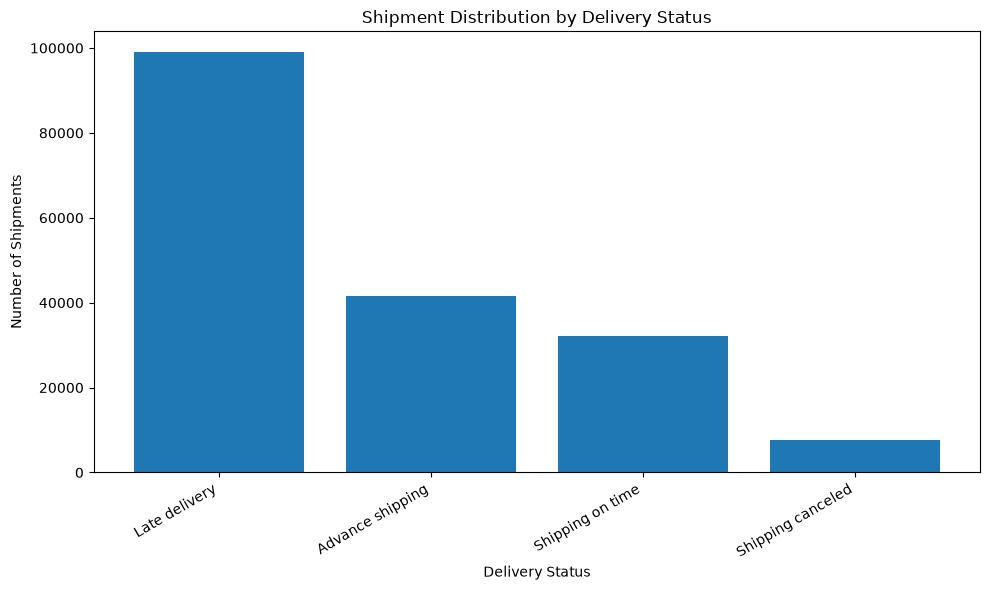

In [42]:
plt.figure(figsize=(10, 6))

plt.bar(
    delivery_status_summary["Delivery_Status"].astype(str),
    delivery_status_summary["Total_Shipments"]
)

plt.title("Shipment Distribution by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Visualization 2: Order Status Distribution

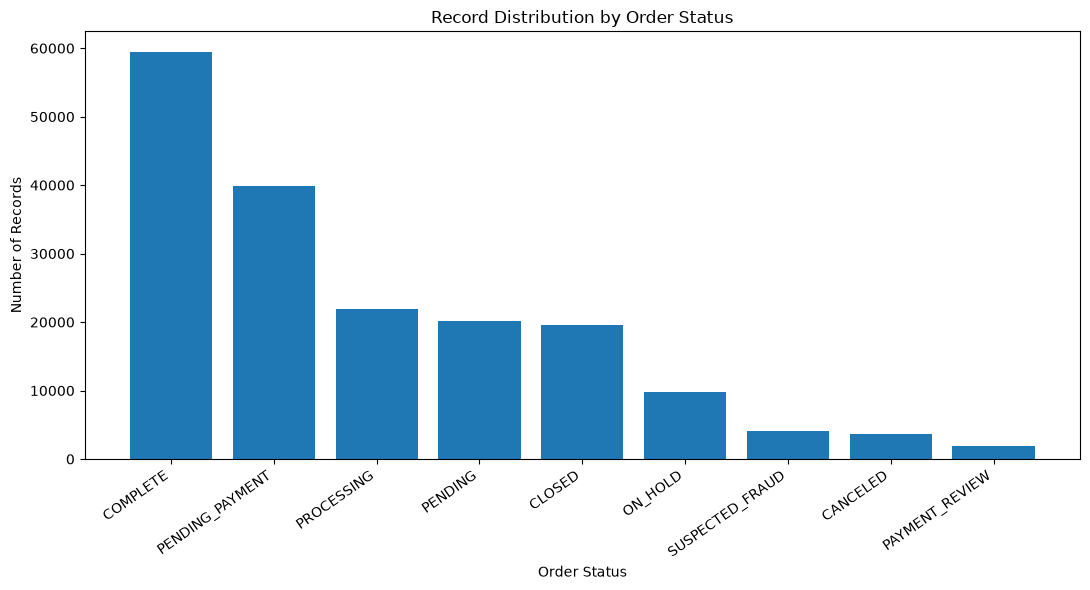

In [43]:
plt.figure(figsize=(11, 6))

plt.bar(
    order_status_summary["Order_Status"].astype(str),
    order_status_summary["Total_Orders"]
)

plt.title("Record Distribution by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Records")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Visualization 3: Actual Delay Rate by Delivery Status

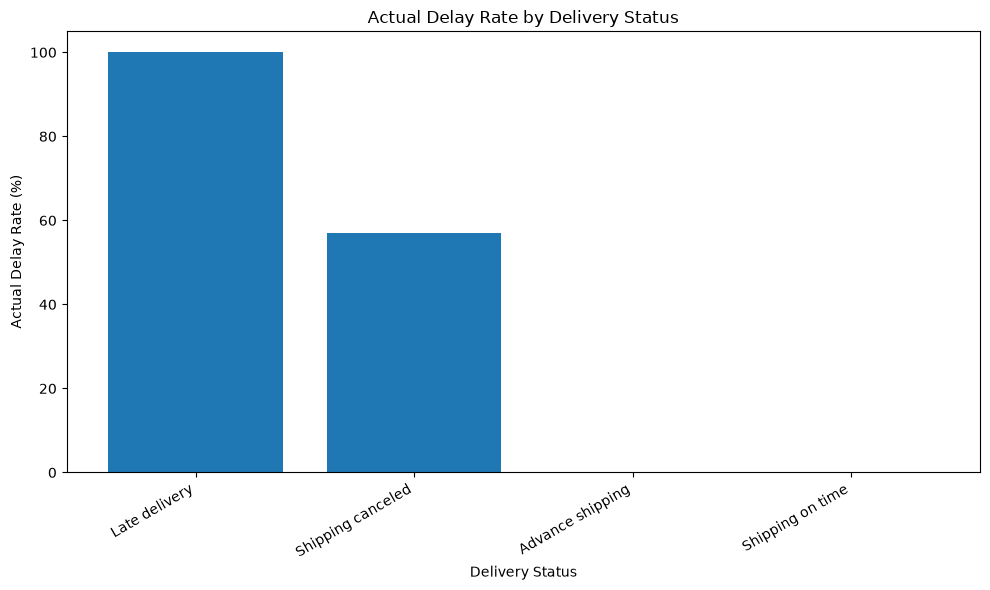

In [44]:
delivery_delay_plot = (
    delivery_delay_analysis
    .reset_index()
    .sort_values("Actual_Delay_Rate_%", ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    delivery_delay_plot["Delivery Status"].astype(str),
    delivery_delay_plot["Actual_Delay_Rate_%"]
)

plt.title("Actual Delay Rate by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Actual Delay Rate (%)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Visualization 4: Actual Delay Rate by Order Status

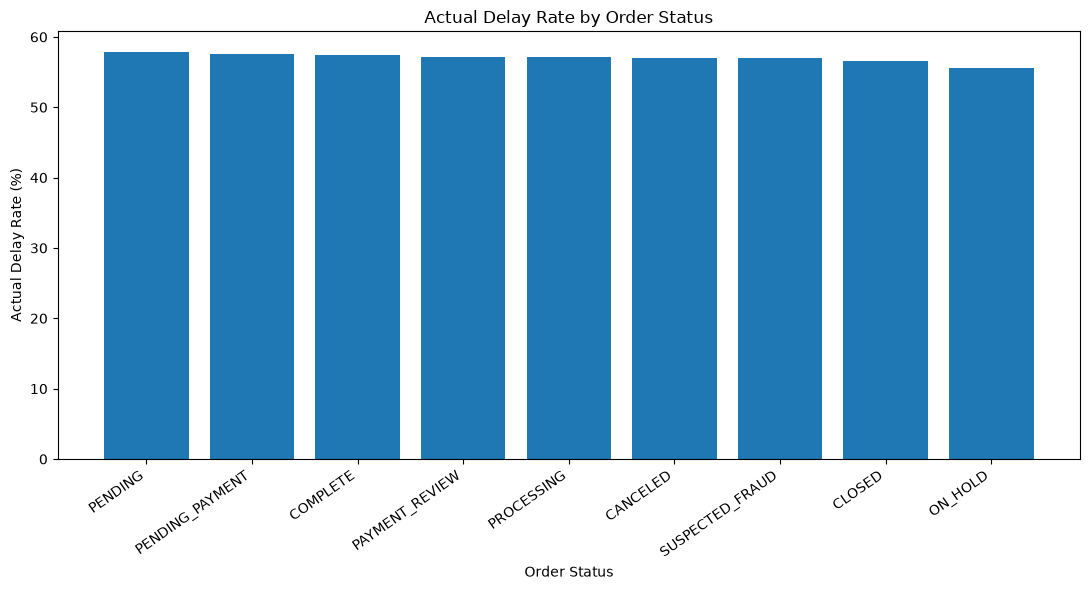

In [45]:
order_delay_plot = (
    order_delay_analysis
    .reset_index()
    .sort_values("Actual_Delay_Rate_%", ascending=False)
)

plt.figure(figsize=(11, 6))

plt.bar(
    order_delay_plot["Order Status"].astype(str),
    order_delay_plot["Actual_Delay_Rate_%"]
)

plt.title("Actual Delay Rate by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Actual Delay Rate (%)")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Optional fifth visualization

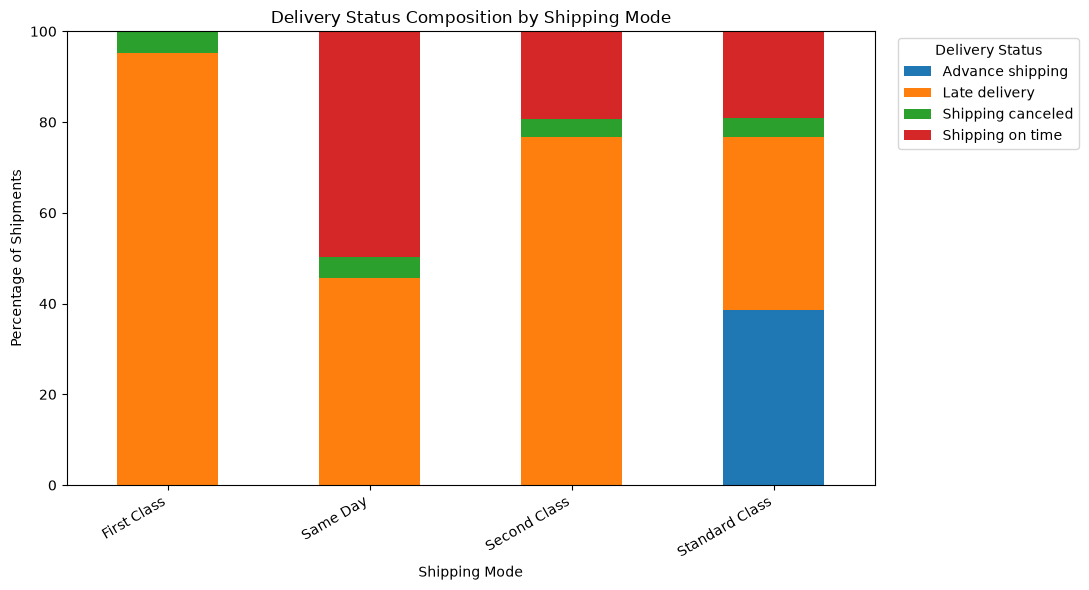

In [46]:
delivery_status_by_mode.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Delivery Status Composition by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Percentage of Shipments")

plt.xticks(rotation=30, ha="right")
plt.legend(
    title="Delivery Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## Day 7 KPI Summary

In [47]:
day7_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipment Records",
        "Unique Delivery Statuses",
        "Unique Order Statuses",
        "Missing Delivery Status Records",
        "Missing Order Status Records",
        "Overall Actual Delay Rate (%)",
        "Most Common Delivery Status",
        "Most Common Order Status",
        "Highest Delay Rate Delivery Status",
        "Highest Delay Rate Order Status"
    ],

    "Value": [
        len(df_day7),

        df_day7["Delivery Status"].nunique(dropna=True),

        df_day7["Order Status"].nunique(dropna=True),

        df_day7["Delivery Status"].isna().sum(),

        df_day7["Order Status"].isna().sum(),

        round(df_day7["Is_Delayed"].mean() * 100, 2),

        df_day7["Delivery Status"].mode().iloc[0]
        if not df_day7["Delivery Status"].mode().empty
        else "Unavailable",

        df_day7["Order Status"].mode().iloc[0]
        if not df_day7["Order Status"].mode().empty
        else "Unavailable",

        delivery_delay_analysis["Actual_Delay_Rate_%"].idxmax()
        if not delivery_delay_analysis.empty
        else "Unavailable",

        order_delay_analysis["Actual_Delay_Rate_%"].idxmax()
        if not order_delay_analysis.empty
        else "Unavailable"
    ]
})

display(day7_kpis)

,Metric,Value
0,Total Shipment Records,180519
1,Unique Delivery Statuses,4
2,Unique Order Statuses,9
3,Missing Delivery Status Records,0
4,Missing Order Status Records,0
5,Overall Actual Delay Rate (%),57.28
6,Most Common Delivery Status,Late delivery
7,Most Common Order Status,COMPLETE
8,Highest Delay Rate Delivery Status,Late delivery
9,Highest Delay Rate Order Status,PENDING


## Validation Report 

In [48]:
validation_report = pd.DataFrame({
    "Validation Check": [
        "Dataset Loaded",
        "Delivery Status Analysis Available",
        "Order Status Analysis Available",
        "Delivery Delay Analysis Available",
        "Order Delay Analysis Available",
        "Delivery Status by Mode Analysis Available",
        "Order Status by Market Analysis Available",
        "KPI Summary Available"
    ],

    "Result": [
        "PASS" if not df_day7.empty else "FAIL",
        "PASS" if not delivery_status_summary.empty else "FAIL",
        "PASS" if not order_status_summary.empty else "FAIL",
        "PASS" if not delivery_delay_analysis.empty else "FAIL",
        "PASS" if not order_delay_analysis.empty else "FAIL",
        "PASS" if not delivery_status_by_mode.empty else "FAIL",
        "PASS" if not order_status_by_market.empty else "FAIL",
        "PASS" if not day7_kpis.empty else "FAIL"
    ]
})

display(validation_report)

print("Day 7 validation report created successfully.")

,Validation Check,Result
0,Dataset Loaded,PASS
1,Delivery Status Analysis Available,PASS
2,Order Status Analysis Available,PASS
3,Delivery Delay Analysis Available,PASS
4,Order Delay Analysis Available,PASS
5,Delivery Status by Mode Analysis Available,PASS
6,Order Status by Market Analysis Available,PASS
7,KPI Summary Available,PASS


Day 7 validation report created successfully.


## Saving Day 7 Outputs

In [49]:
day7_output_dir = "../data/analysis_data/"

day7_outputs = {
    "APL_Day7_Delivery_Status_Analysis.csv":
        delivery_status_summary,

    "APL_Day7_Order_Status_Analysis.csv":
        order_status_summary,

    "APL_Day7_Delivery_Delay_Analysis.csv":
        delivery_delay_analysis.reset_index(),

    "APL_Day7_Order_Delay_Analysis.csv":
        order_delay_analysis.reset_index(),

    "APL_Day7_Delivery_Status_by_Mode.csv":
        delivery_status_by_mode.reset_index(),

    "APL_Day7_Order_Status_by_Market.csv":
        order_status_by_market.reset_index(),

    "APL_Day7_KPIs.csv":
        day7_kpis,

    "APL_Day7_Validation.csv":
        validation_report
}

for filename, output_df in day7_outputs.items():

    output_path = day7_output_dir + filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    print("Saved:", output_path)

print("\nAll Day 7 outputs saved successfully.")

Saved: ../data/analysis_data/APL_Day7_Delivery_Status_Analysis.csv
Saved: ../data/analysis_data/APL_Day7_Order_Status_Analysis.csv
Saved: ../data/analysis_data/APL_Day7_Delivery_Delay_Analysis.csv
Saved: ../data/analysis_data/APL_Day7_Order_Delay_Analysis.csv
Saved: ../data/analysis_data/APL_Day7_Delivery_Status_by_Mode.csv
Saved: ../data/analysis_data/APL_Day7_Order_Status_by_Market.csv
Saved: ../data/analysis_data/APL_Day7_KPIs.csv
Saved: ../data/analysis_data/APL_Day7_Validation.csv

All Day 7 outputs saved successfully.
